In [1]:
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns

# Montar Google Drive
drive.mount('/content/drive')

# Definir la ruta base donde están los archivos (se debe ajustar si es necesario)
ruta_base = "/content/drive/My Drive/Colab Notebooks/entrega2/"

Mounted at /content/drive


In [2]:
import pandas as pd

# Ruta con nombre del archivo csv en Google Drive
ruta_csv1 = ruta_base + "Instituciones_Educativas_de_Cauca.csv"
ruta_csv2 = ruta_base + "MEN_ESTADISTICAS_EN_EDUCACION_EN_PREESCOLAR,_BÁSICA_Y_MEDIA_POR_MUNICIPIO.csv"

# Leer archivo CSV delimitado por ','
df_csv1 = pd.read_csv(ruta_csv1, delimiter=",")
df_csv2 = pd.read_csv(ruta_csv2, delimiter=",")

print("\nDatos del archivo CSV:")
print(df_csv1.head())
print(df_csv2.head())



Datos del archivo CSV:
  nombredepartamento nombremunicipio codigoestablecimiento  \
0              CAUCA      SANTA ROSA       219.701.000.155   
1              CAUCA         POPAYÁN       319.001.003.379   
2              CAUCA         POPAYÁN       219.001.004.982   
3              CAUCA         TORIBIO       319.821.000.412   
4              CAUCA   PUERTO TEJADA       219.573.000.082   

                       nombreestablecimiento    zona  \
0  I.E. SANTA MARTA ANTES (C.E. SANTA MARTA)   RURAL   
1                      LICEO BELLO HORIZONTE  URBANA   
2             I.E. DEL RESGUARDO DE QUINTANA   RURAL   
3                I.E. TECNICA EDUARDO SANTOS   RURAL   
4                            C.E. LAS BRISAS   RURAL   

                    direccion    telefono  \
0  KM 27 VIA MOCOA - PITALITO  3147557759   
1                 CL 67 13 30     8247443   
2            VDA. LAS PIEDRAS         NaN   
3           VEREDA LA BETULIA  3216450576   
4          VEREDA LAS  BRISAS  3217248180

In [3]:
df_cauca1 = df_csv1[(df_csv1['nombredepartamento'] =="CAUCA" )]
print(df_cauca1)
df_cauca2=df_csv2[(df_csv2['DEPARTAMENTO'] =="Cauca" )  & (df_csv2['AÑO'] ==2024 )]
print(df_cauca2)

    nombredepartamento nombremunicipio codigoestablecimiento  \
0                CAUCA      SANTA ROSA       219.701.000.155   
1                CAUCA         POPAYÁN       319.001.003.379   
2                CAUCA         POPAYÁN       219.001.004.982   
3                CAUCA         TORIBIO       319.821.000.412   
4                CAUCA   PUERTO TEJADA       219.573.000.082   
..                 ...             ...                   ...   
809              CAUCA          BALBOA       219.075.000.245   
810              CAUCA         POPAYÁN       319.001.005.142   
811              CAUCA         POPAYÁN       319.001.005.240   
812              CAUCA         MIRANDA       319.455.000.731   
813              CAUCA          PURACÉ       219.585.000.142   

                         nombreestablecimiento    zona  \
0    I.E. SANTA MARTA ANTES (C.E. SANTA MARTA)   RURAL   
1                        LICEO BELLO HORIZONTE  URBANA   
2               I.E. DEL RESGUARDO DE QUINTANA   RURAL   

In [4]:
lista_variables = df_cauca2.columns.tolist()
print(lista_variables)

['AÑO', 'CÓDIGO_MUNICIPIO', 'MUNICIPIO', 'CÓDIGO_DEPARTAMENTO', 'DEPARTAMENTO', 'CÓDIGO_ETC', 'ETC', 'POBLACIÓN_5_16', 'TASA_MATRICULACIÓN_5_16', 'COBERTURA_NETA', 'COBERTURA_NETA_TRANSICIÓN', 'COBERTURA_NETA_PRIMARIA', 'COBERTURA_NETA_SECUNDARIA', 'COBERTURA_NETA_MEDIA', 'COBERTURA_BRUTA', 'COBERTURA_BRUTA_TRANSICIÓN', 'COBERTURA_BRUTA_PRIMARIA', 'COBERTURA_BRUTA_SECUNDARIA', 'COBERTURA_BRUTA_MEDIA', 'TAMAÑO_PROMEDIO_DE_GRUPO', 'SEDES_CONECTADAS_A_INTERNET', 'DESERCIÓN', 'DESERCIÓN_TRANSICIÓN', 'DESERCIÓN_PRIMARIA', 'DESERCIÓN_SECUNDARIA', 'DESERCIÓN_MEDIA', 'APROBACIÓN', 'APROBACIÓN_TRANSICIÓN', 'APROBACIÓN_PRIMARIA', 'APROBACIÓN_SECUNDARIA', 'APROBACIÓN_MEDIA', 'REPROBACIÓN', 'REPROBACIÓN_TRANSICIÓN', 'REPROBACIÓN_PRIMARIA', 'REPROBACIÓN_SECUNDARIA', 'REPROBACIÓN_MEDIA', 'REPITENCIA', 'REPITENCIA_TRANSICIÓN', 'REPITENCIA_PRIMARIA', 'REPITENCIA_SECUNDARIA', 'REPITENCIA_MEDIA']


In [11]:
df_cauca = pd.DataFrame(df_cauca2)

# 2. DEFINIR LA LISTA DE COLUMNAS QUE TIENEN EL SÍMBOLO %
columnas_porcentaje = ["TASA_MATRICULACIÓN_5_16", "COBERTURA_NETA", "COBERTURA_NETA_TRANSICIÓN",
                       "COBERTURA_NETA_PRIMARIA", "COBERTURA_NETA_SECUNDARIA", "COBERTURA_NETA_MEDIA",
                       "COBERTURA_BRUTA", "COBERTURA_BRUTA_TRANSICIÓN", "COBERTURA_BRUTA_PRIMARIA",
                       "COBERTURA_BRUTA_SECUNDARIA", "COBERTURA_BRUTA_MEDIA", "TAMAÑO_PROMEDIO_DE_GRUPO",
                       "SEDES_CONECTADAS_A_INTERNET", "DESERCIÓN", "DESERCIÓN_TRANSICIÓN", "DESERCIÓN_PRIMARIA",
                       "DESERCIÓN_SECUNDARIA", "DESERCIÓN_MEDIA", "APROBACIÓN", "APROBACIÓN_TRANSICIÓN",
                       "APROBACIÓN_PRIMARIA", "APROBACIÓN_SECUNDARIA", "APROBACIÓN_MEDIA", "REPROBACIÓN",
                       "REPROBACIÓN_TRANSICIÓN", "REPROBACIÓN_PRIMARIA", "REPROBACIÓN_SECUNDARIA", "REPROBACIÓN_MEDIA",
                       "REPITENCIA", "REPITENCIA_TRANSICIÓN", "REPITENCIA_PRIMARIA", "REPITENCIA_SECUNDARIA", "REPITENCIA_MEDIA"]

# 3. RECORRER Y LIMPIAR CADA COLUMNA EN UN BUCLE
for col in columnas_porcentaje:
    df_cauca[col] = (
        df_cauca[col]
        .astype(str)  # Asegura que se lea como texto
        .str.replace("%", "", regex=False)  # Quita el %
        .str.replace(",", ".", regex=False)  # Cambia coma por punto
        .astype(float)  # Convierte a número decimal
        / 100
    )  # Opcional: divide por 100 si quieres proporciones (ej: 0.0497)

print(df_cauca)


# Estandarizar los valores de la columna 'zona' en df_cauca1
# Definimos un mapeo para unificar 'URBANA,RURAL' y 'RURAL,URBANA'
reemplazos_zona = {
    'URBANA,RURAL': 'URBANA-RURAL',
    'RURAL,URBANA': 'URBANA-RURAL'
}

df_cauca1['zona'] = df_cauca1['zona'].replace(reemplazos_zona)

# Mostrar la distribución actualizada de la columna 'zona'
print("Valores únicos y frecuencias en la columna 'zona' después de la limpieza:")
print(df_cauca1['zona'].value_counts(dropna=False))


      AÑO  CÓDIGO_MUNICIPIO               MUNICIPIO  CÓDIGO_DEPARTAMENTO  \
543  2024             19212                 Corinto                   19   
725  2024             19845              Villa Rica                   19   
726  2024             19824                  Totoró                   19   
727  2024             19821                 Toribio                   19   
728  2024             19809                Timbiquí                   19   
729  2024             19807                  Timbío                   19   
730  2024             19785                   Sucre                   19   
731  2024             19780                  Suárez                   19   
732  2024             19760                  Sotara                   19   
733  2024             19743                  Silvia                   19   
734  2024             19701              Santa Rosa                   19   
735  2024             19698  Santander de Quilichao                   19   
736  2024   

In [6]:


# Obtener los valores de la media del DataFrame reporte_calidad
media_values = reporte_calidad['Media']

# Crear el gráfico de barras
plt.figure(figsize=(12, 7))
sns.barplot(x=media_values.index, y=media_values.values, palette='viridis')

plt.title('Valores Medios de las Variables de Interés', fontsize=16)
plt.xlabel('Variable', fontsize=12)
plt.ylabel('Valor de la Media', fontsize=12)
plt.xticks(rotation=45, ha='right') # Rotar etiquetas para mejor legibilidad
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

NameError: name 'reporte_calidad' is not defined

/tmp/ipykernel_1261/151466164.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='MUNICIPIO', y='DESERCIÓN', data=deserción_por_municipio, palette='viridis')


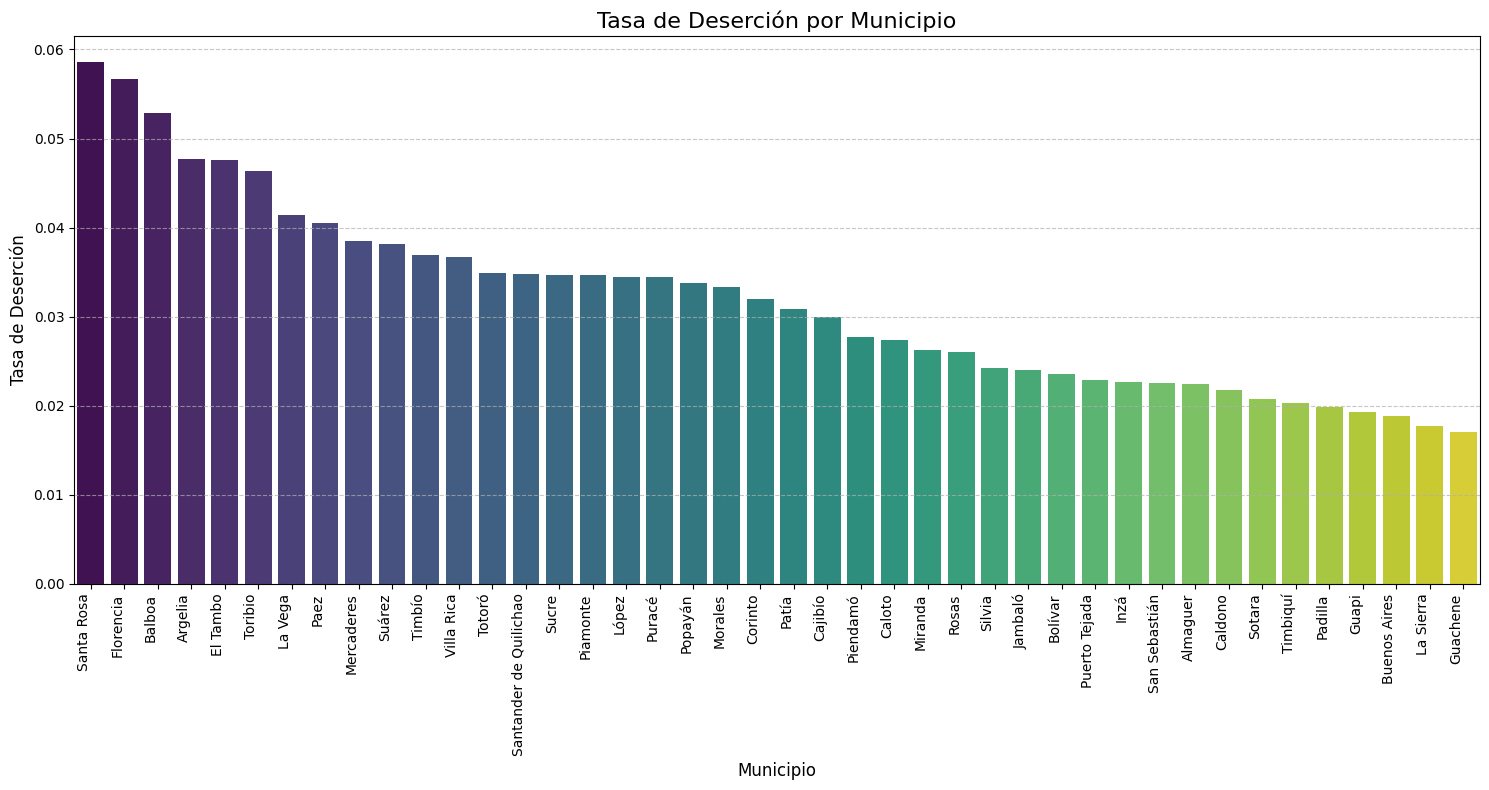

In [12]:

deserción_por_municipio = df_cauca[['MUNICIPIO', 'DESERCIÓN']].sort_values(by='DESERCIÓN', ascending=False)

plt.figure(figsize=(15, 8))
sns.barplot(x='MUNICIPIO', y='DESERCIÓN', data=deserción_por_municipio, palette='viridis')

plt.title('Tasa de Deserción por Municipio', fontsize=16)
plt.xlabel('Municipio', fontsize=12)
plt.ylabel('Tasa de Deserción', fontsize=12)
plt.xticks(rotation=90, ha='right') # Rotar etiquetas para mejor legibilidad
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1261/3576070409.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='zona', data=df_cauca1, palette='pastel', order=df_cauca1['zona'].value_counts().index)


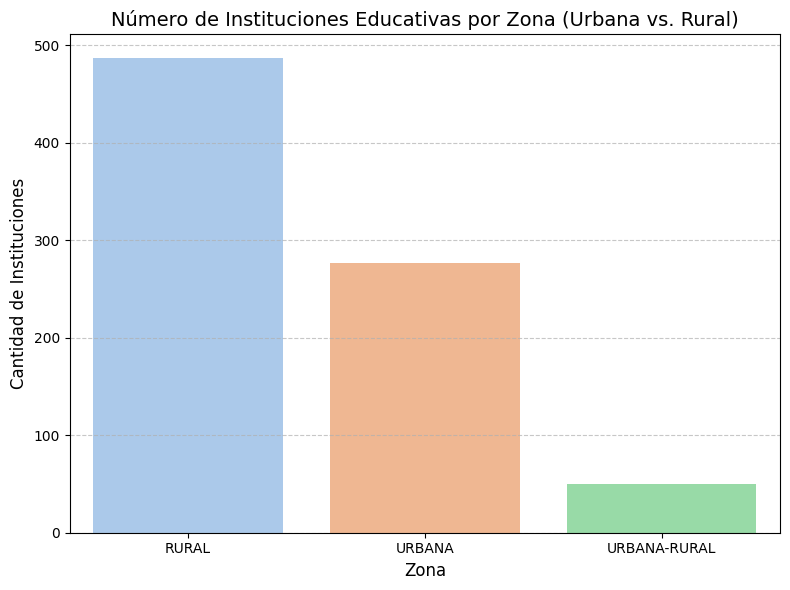

In [13]:

plt.figure(figsize=(8, 6))
sns.countplot(x='zona', data=df_cauca1, palette='pastel', order=df_cauca1['zona'].value_counts().index)
plt.title('Número de Instituciones Educativas por Zona (Urbana vs. Rural)', fontsize=14)
plt.xlabel('Zona', fontsize=12)
plt.ylabel('Cantidad de Instituciones', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1261/4239863125.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Cantidad de Colegios Rurales', y='Municipio', data=colegios_rurales_por_municipio, palette='rocket')


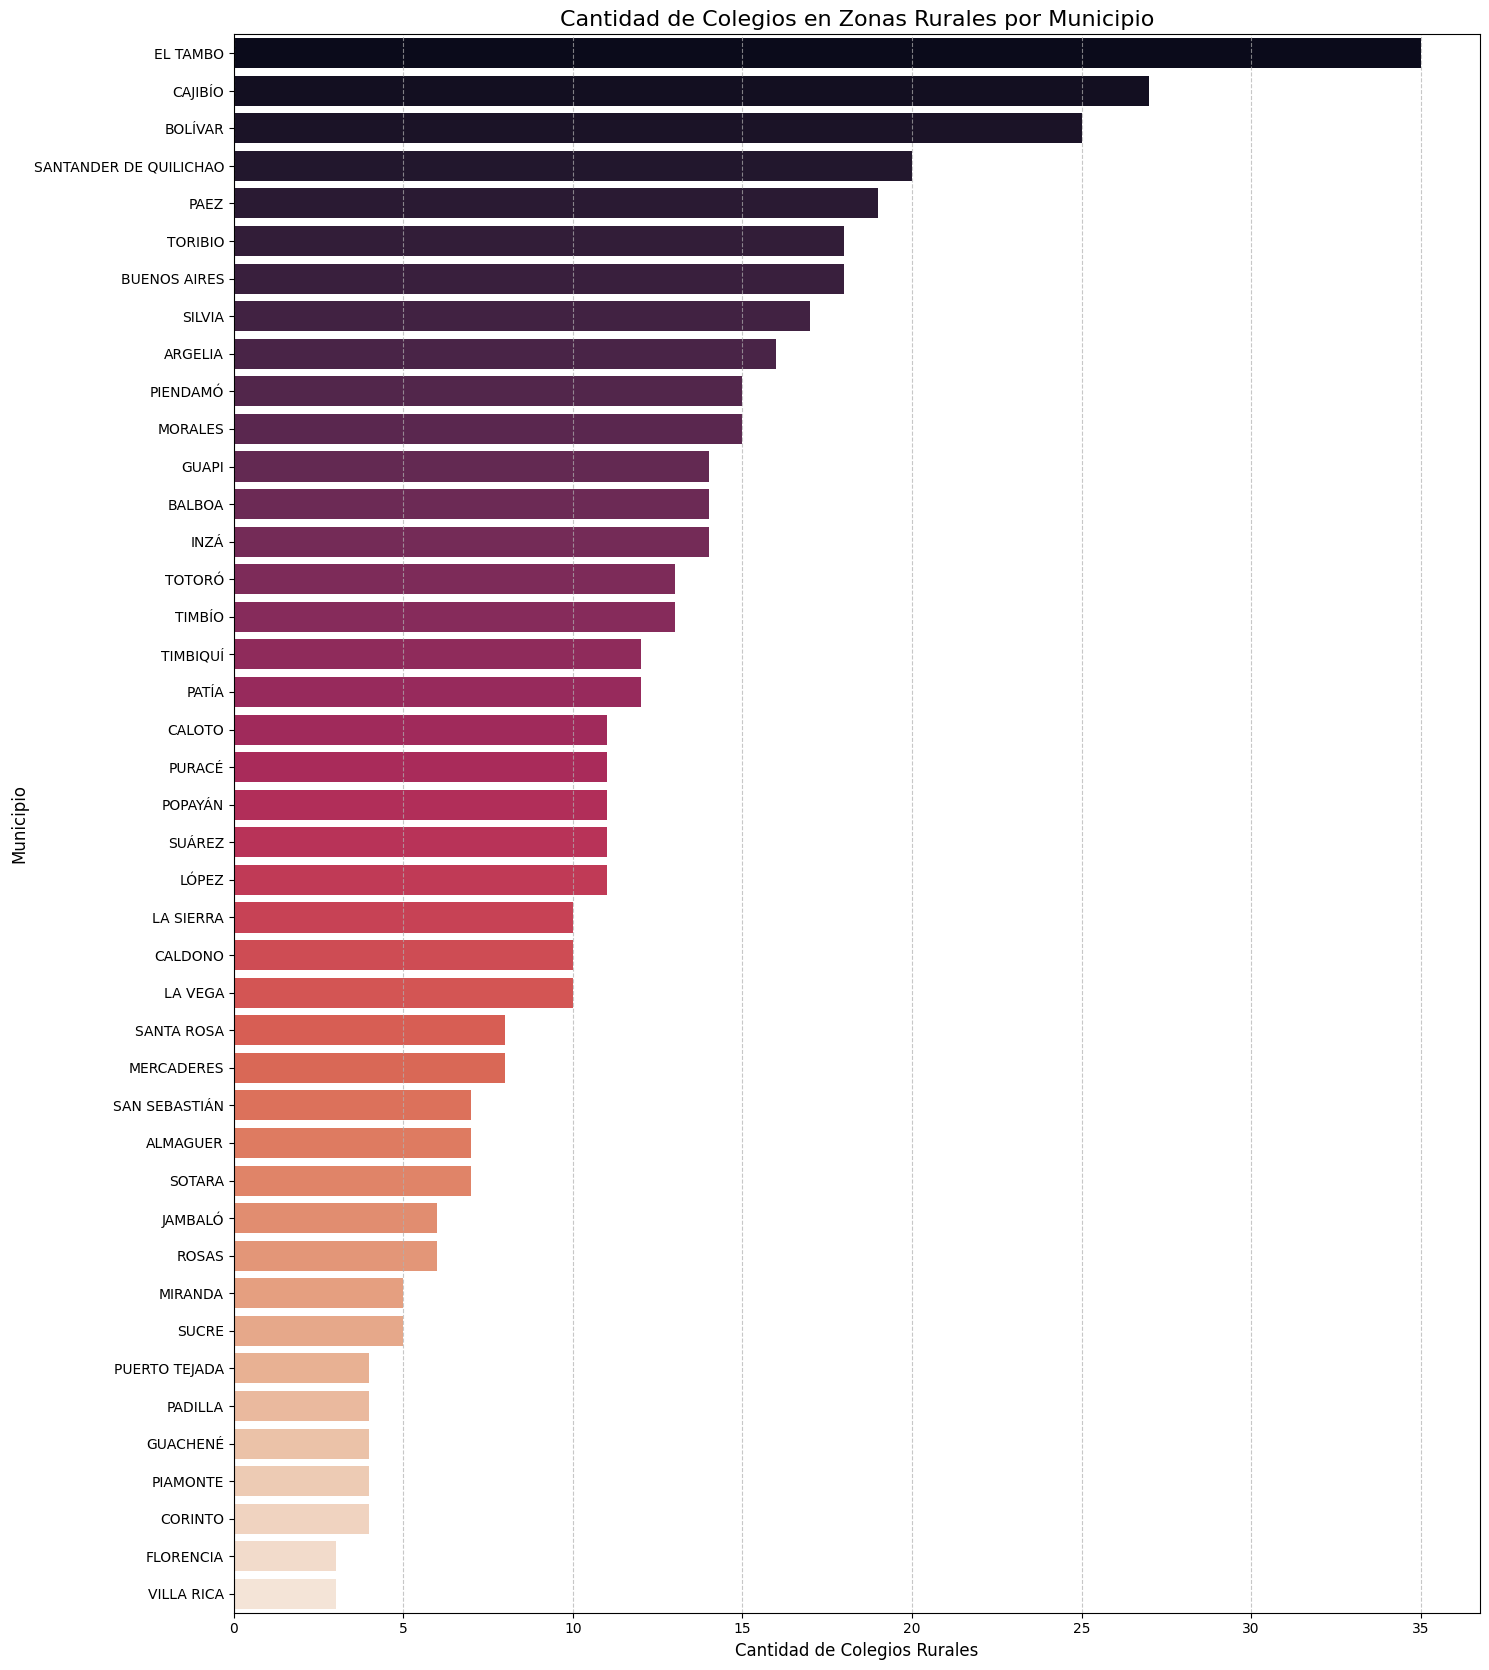

In [14]:

# Filtrar df_cauca1 para obtener solo instituciones en zona rural
df_rural = df_cauca1[df_cauca1['zona'] == 'RURAL']

# Contar la cantidad de colegios rurales por municipio
colegios_rurales_por_municipio = df_rural['nombremunicipio'].value_counts().reset_index()
colegios_rurales_por_municipio.columns = ['Municipio', 'Cantidad de Colegios Rurales']

# Ordenar para una mejor visualización
colegios_rurales_por_municipio = colegios_rurales_por_municipio.sort_values(by='Cantidad de Colegios Rurales', ascending=False)

plt.figure(figsize=(15, max(8, len(colegios_rurales_por_municipio) * 0.4)))
sns.barplot(x='Cantidad de Colegios Rurales', y='Municipio', data=colegios_rurales_por_municipio, palette='rocket')

plt.title('Cantidad de Colegios en Zonas Rurales por Municipio', fontsize=16)
plt.xlabel('Cantidad de Colegios Rurales', fontsize=12)
plt.ylabel('Municipio', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()